# Week 05 感知机从零实现——基于乳腺癌数据的二分类

## 1. 实验目的

本实验使用 Scikit-learn 提供的 Breast Cancer Wisconsin 数据集，
从零实现感知机（Perceptron）二分类算法，并与 Scikit-learn 中的
Perceptron 模型进行对比。

通过本实验理解感知机的基本原理、误分类点的参数更新规则，
掌握感知机模型的训练与评估方法。

## 2. 数据集加载与基本分析

本实验使用 Scikit-learn 提供的 Breast Cancer Wisconsin 数据集。
该数据集是一个经典的二分类数据集，通过乳腺肿瘤的多项特征判断肿瘤属于恶性（malignant）还是良性（benign）。

下面加载数据集并查看数据的基本信息。

In [1]:
from sklearn.datasets import load_breast_cancer
import pandas as pd
import numpy as np

# 加载数据集
data = load_breast_cancer()

# 查看数据集基本信息
print("特征数据形状：", data.data.shape)
print("标签形状：", data.target.shape)
print("类别名称：", data.target_names)
print("特征数量：", len(data.feature_names))
print("特征名称：")
print(data.feature_names)

特征数据形状： (569, 30)
标签形状： (569,)
类别名称： ['malignant' 'benign']
特征数量： 30
特征名称：
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [2]:
# 转换成 DataFrame，方便观察
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

print("数据集形状：", df.shape)
display(df.head())

数据集形状： (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
print("类别数量：")
print(df["target"].value_counts())

print("\n类别比例：")
print(df["target"].value_counts(normalize=True))

类别数量：
target
1    357
0    212
Name: count, dtype: int64

类别比例：
target
1    0.627417
0    0.372583
Name: proportion, dtype: float64


## 3. 数据预处理

经典感知机模型通常使用 {-1, +1} 作为类别标签，因此首先将原数据集中的
0 和 1 分别转换为 -1 和 +1。

随后将数据划分为训练集和测试集，并对特征进行标准化处理。

In [5]:
# 获取特征和标签
X = data.data
y = data.target.copy()

# 将标签从 {0, 1} 转换为 {-1, +1}
y = np.where(y == 0, -1, 1)

print("转换后的标签：", np.unique(y))
print("-1 类样本数：", np.sum(y == -1))
print("+1 类样本数：", np.sum(y == 1))

转换后的标签： [-1  1]
-1 类样本数： 212
+1 类样本数： 357


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("训练集特征形状：", X_train.shape)
print("测试集特征形状：", X_test.shape)
print("训练集标签形状：", y_train.shape)
print("测试集标签形状：", y_test.shape)

print("\n训练集类别分布：")
print("-1：", np.sum(y_train == -1))
print("+1：", np.sum(y_train == 1))

print("\n测试集类别分布：")
print("-1：", np.sum(y_test == -1))
print("+1：", np.sum(y_test == 1))

训练集特征形状： (455, 30)
测试集特征形状： (114, 30)
训练集标签形状： (455,)
测试集标签形状： (114,)

训练集类别分布：
-1： 170
+1： 285

测试集类别分布：
-1： 42
+1： 72


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# 只使用训练集计算均值和标准差
X_train_scaled = scaler.fit_transform(X_train)

# 测试集使用训练集得到的参数进行转换
X_test_scaled = scaler.transform(X_test)

print("标准化前训练集第一个样本前5个特征：")
print(X_train[0][:5])

print("\n标准化后训练集第一个样本前5个特征：")
print(X_train_scaled[0][:5])

print("\n标准化后训练集各特征均值（前5个）：")
print(X_train_scaled.mean(axis=0)[:5])

print("\n标准化后训练集各特征标准差（前5个）：")
print(X_train_scaled.std(axis=0)[:5])

标准化前训练集第一个样本前5个特征：
[1.032e+01 1.635e+01 6.531e+01 3.249e+02 9.434e-02]

标准化后训练集第一个样本前5个特征：
[-1.07200079 -0.6584246  -1.0880801  -0.93927364 -0.13593988]

标准化后训练集各特征均值（前5个）：
[-4.31742554e-15  2.24606658e-15 -7.38359313e-16  1.71779562e-16
  5.22695440e-15]

标准化后训练集各特征标准差（前5个）：
[1. 1. 1. 1. 1.]


## 4. 从零实现感知机

感知机是一种线性二分类模型，其分类函数为：

\[
f(x)=\operatorname{sign}(w \cdot x+b)
\]

对于误分类样本 $(x_i,y_i)$，满足：

\[
y_i(w\cdot x_i+b)\leq 0
\]

此时按照以下规则更新参数：

\[
w \leftarrow w+\eta y_i x_i
\]

\[
b \leftarrow b+\eta y_i
\]

其中 $\eta$ 为学习率。

下面使用 NumPy 从零实现感知机学习算法。

In [8]:
class MyPerceptron:
    def __init__(self, learning_rate=0.01, epochs=100):
        # 学习率
        self.learning_rate = learning_rate
        
        # 最大训练轮数
        self.epochs = epochs
        
        # 权重和偏置
        self.w = None
        self.b = None
        
        # 记录每一轮的误分类样本数量
        self.errors_history = []

    def fit(self, X, y):
        # 获取样本数量和特征数量
        n_samples, n_features = X.shape
        
        # 初始化参数
        self.w = np.zeros(n_features)
        self.b = 0.0

        # 开始训练
        for epoch in range(self.epochs):
            errors = 0

            # 依次遍历训练样本
            for xi, yi in zip(X, y):
                
                # 判断当前样本是否被误分类
                if yi * (np.dot(self.w, xi) + self.b) <= 0:
                    
                    # 更新 w
                    self.w += self.learning_rate * yi * xi
                    
                    # 更新 b
                    self.b += self.learning_rate * yi
                    
                    # 记录误分类次数
                    errors += 1

            # 保存这一轮的误分类数量
            self.errors_history.append(errors)

        return self

    def predict(self, X):
        # 计算 w·x+b
        scores = X @ self.w + self.b
        
        # 大于等于0预测为+1，否则预测为-1
        return np.where(scores >= 0, 1, -1)

## 5. 手写感知机训练

使用标准化后的训练数据训练手写感知机模型。

设置学习率为 0.01，最大训练轮数为 100，并记录每一轮训练过程中发生的误分类次数，以观察模型的训练过程。

In [9]:
# 创建手写感知机模型
model = MyPerceptron(
    learning_rate=0.01,
    epochs=100
)

# 训练模型
model.fit(X_train_scaled, y_train)

print("训练完成！")
print("权重数量：", len(model.w))
print("最终偏置 b：", model.b)

print("\n前10轮误分类次数：")
print(model.errors_history[:10])

print("\n最后10轮误分类次数：")
print(model.errors_history[-10:])

训练完成！
权重数量： 30
最终偏置 b： -0.04

前10轮误分类次数：
[24, 12, 15, 16, 11, 11, 14, 8, 15, 14]

最后10轮误分类次数：
[10, 12, 13, 9, 3, 13, 10, 7, 12, 12]


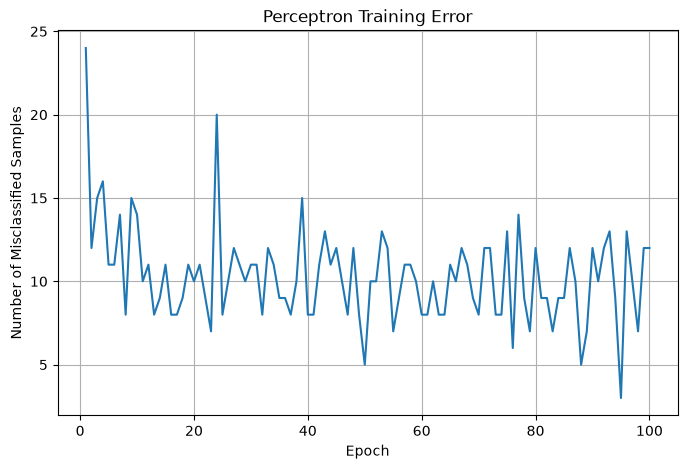

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(model.errors_history) + 1),
    model.errors_history
)

plt.xlabel("Epoch")
plt.ylabel("Number of Misclassified Samples")
plt.title("Perceptron Training Error")
plt.grid(True)

plt.show()

In [11]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 在测试集上进行预测
y_pred = model.predict(X_test_scaled)

# 计算准确率
accuracy = accuracy_score(y_test, y_pred)

print("手写感知机测试集准确率：", accuracy)
print(f"手写感知机测试集准确率：{accuracy * 100:.2f}%")

print("\n混淆矩阵：")
print(confusion_matrix(y_test, y_pred))

print("\n分类报告：")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["malignant", "benign"]
    )
)

手写感知机测试集准确率： 0.9649122807017544
手写感知机测试集准确率：96.49%

混淆矩阵：
[[41  1]
 [ 3 69]]

分类报告：
              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



## 8. 与 Scikit-learn Perceptron 对比

为了验证手写感知机算法的有效性，使用 Scikit-learn 提供的
Perceptron 模型在相同的训练集和测试集上进行训练和预测，
并比较两个模型的分类性能。

In [14]:
from sklearn.linear_model import Perceptron

# 创建 sklearn 感知机模型
sk_model = Perceptron(
    eta0=0.01,
    max_iter=100,
    random_state=42
)

# 训练模型
sk_model.fit(X_train_scaled, y_train)

# 测试集预测
y_pred_sk = sk_model.predict(X_test_scaled)

# 准确率
accuracy_sk = accuracy_score(y_test, y_pred_sk)

print(f"sklearn 感知机测试集准确率：{accuracy_sk * 100:.2f}%")

print("\n混淆矩阵：")
print(confusion_matrix(y_test, y_pred_sk))

print("\n分类报告：")
print(
    classification_report(
        y_test,
        y_pred_sk,
        target_names=["malignant", "benign"]
    )
)

sklearn 感知机测试集准确率：96.49%

混淆矩阵：
[[41  1]
 [ 3 69]]

分类报告：
              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



In [13]:
print("===== 手写感知机与 sklearn 对比 =====")

print(f"手写感知机准确率：   {accuracy * 100:.2f}%")
print(f"sklearn 感知机准确率：{accuracy_sk * 100:.2f}%")

print(
    "准确率差异：",
    f"{abs(accuracy - accuracy_sk) * 100:.2f} 个百分点"
)

===== 手写感知机与 sklearn 对比 =====
手写感知机准确率：   96.49%
sklearn 感知机准确率：96.49%
准确率差异： 0.00 个百分点


## 9. 实验结果分析

本实验使用 Breast Cancer Wisconsin 数据集进行乳腺肿瘤二分类，
并分别使用手写感知机和 Scikit-learn Perceptron 进行实验。

### 9.1 手写感知机实验结果

手写感知机在测试集上的分类结果如下：

- 测试集样本数：114
- 测试集准确率：96.49%
- 恶性样本数量：42
- 正确识别恶性样本：41
- 恶性样本召回率：97.62%
- 良性样本数量：72
- 正确识别良性样本：69

混淆矩阵为：

| 真实类别 | 预测恶性 | 预测良性 |
| --- | ---: | ---: |
| 恶性 | 41 | 1 |
| 良性 | 3 | 69 |

模型共正确预测 110 个样本，错误预测 4 个样本。

### 9.2 训练过程分析

训练过程中，每轮发生的误分类次数存在一定波动，并没有随着训练轮数增加而严格单调下降。
例如前 10 轮的误分类次数为：

`[24, 12, 15, 16, 11, 11, 14, 8, 15, 14]`

最后 10 轮为：

`[10, 12, 13, 9, 3, 13, 10, 7, 12, 12]`

这是因为感知机在遇到误分类样本时会立即更新模型参数，一次参数更新可能改变其他样本的分类结果。
同时，真实数据集并不一定严格线性可分，因此训练过程中的误分类次数不一定最终下降到 0。

尽管如此，模型在测试集上仍取得了 96.49% 的准确率，说明学习得到的线性分类边界具有较好的分类能力。

### 9.3 与 Scikit-learn 对比

| 模型 | 测试集准确率 |
| --- | ---: |
| 手写感知机 | 96.49% |
| Scikit-learn Perceptron | 96.49% |

两个模型的测试集准确率均为 96.49%，混淆矩阵也完全一致，
均正确分类 110 个测试样本，仅错误分类 4 个样本。

实验结果表明，本实验从零实现的感知机能够正确完成参数更新和二分类任务，
其分类性能与 Scikit-learn Perceptron 在本次实验设置下保持一致。

## 10. 实验总结

本实验基于 Breast Cancer Wisconsin 数据集完成了感知机二分类实验。

首先对数据集进行训练集和测试集划分，并使用 StandardScaler 对特征进行标准化。
随后使用 NumPy 从零实现感知机算法，根据误分类条件

\[
y_i(w\cdot x_i+b)\leq0
\]

判断误分类样本，并按照

\[
w \leftarrow w+\eta y_i x_i
\]

\[
b \leftarrow b+\eta y_i
\]

更新模型参数。

实验结果表明，手写感知机在测试集上取得了 96.49% 的准确率，
与 Scikit-learn Perceptron 的测试结果一致。

通过本实验进一步理解了感知机的线性分类原理、误分类判断条件和参数更新过程，
同时认识到对于非严格线性可分的数据，感知机训练过程中的误分类次数可能发生波动，
并不一定最终收敛到 0。